# BÀI 2 — HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI CHO BỘ DỮ LIỆU `wine_quality_merged`

### Bài toán
Bộ dữ liệu gộp rượu vang đỏ và trắng (6497 mẫu, 11 chỉ số hóa lý, cột `quality` từ 3–9 và cột `type`). Đề bài không nêu rõ nhãn nên ta đặt bài toán **phân loại nhị phân**:

- `good = 1` nếu `quality >= 7` (rượu chất lượng cao) → lớp cần phát hiện (minority class);
- `good = 0` nếu `quality <= 6`.

Quy trình theo bài thực hành: EDA → Train/Test split (`stratify`) → Pipeline chuẩn hóa → Stratified K-Fold CV → xử lý class imbalance (Over / Under / SMOTE) → so sánh classifier → đánh giá trên test (Confusion Matrix, Classification Report, PR Curve).

## Phần 1. Import thư viện

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, accuracy_score,
                             roc_auc_score, average_precision_score)

RANDOM_STATE = 42

KeyboardInterrupt: 

## Phần 2. Bộ lấy mẫu (sampler) và Pipeline chống data leakage
Bài thực hành dùng `imbalanced-learn`. Để notebook chạy được cả khi chưa cài thư viện này, ta tự viết ba sampler có cùng giao diện `fit_resample` (Random Over-Sampling, Random Under-Sampling, SMOTE) và một `SamplingPipeline` làm đúng thứ tự **StandardScaler → Sampling → Classifier**. Sampling chỉ chạy trong `fit` (tức chỉ trên phần train của từng fold), không bao giờ chạy trên validation/test → không bị leakage.

> Nếu đã cài `imbalanced-learn`, có thể thay bằng `RandomOverSampler`, `RandomUnderSampler`, `SMOTE` và `imblearn.pipeline.Pipeline`; kết quả tương đương.

In [1]:
class RandomOverSampler(BaseEstimator):
    """Nhân bản ngẫu nhiên mẫu minority cho đến khi bằng majority."""
    def __init__(self, random_state=RANDOM_STATE):
        self.random_state = random_state
    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X, y = np.asarray(X), np.asarray(y)
        n1, n0 = (y == 1).sum(), (y == 0).sum()
        idx1 = np.where(y == 1)[0]
        extra = rng.choice(idx1, size=n0 - n1, replace=True)
        keep = np.concatenate([np.arange(len(y)), extra])
        return X[keep], y[keep]

class RandomUnderSampler(BaseEstimator):
    """Bỏ ngẫu nhiên mẫu majority cho đến khi bằng minority."""
    def __init__(self, random_state=RANDOM_STATE):
        self.random_state = random_state
    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X, y = np.asarray(X), np.asarray(y)
        idx1, idx0 = np.where(y == 1)[0], np.where(y == 0)[0]
        keep0 = rng.choice(idx0, size=len(idx1), replace=False)
        keep = np.concatenate([idx1, keep0])
        return X[keep], y[keep]

class SMOTE(BaseEstimator):
    """Sinh mẫu minority tổng hợp bằng nội suy giữa mẫu và k láng giềng gần nhất."""
    def __init__(self, k_neighbors=5, random_state=RANDOM_STATE):
        self.k_neighbors = k_neighbors
        self.random_state = random_state
    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X, y = np.asarray(X), np.asarray(y)
        X1 = X[y == 1]
        n_new = (y == 0).sum() - len(X1)
        nn = NearestNeighbors(n_neighbors=self.k_neighbors + 1).fit(X1)
        neigh = nn.kneighbors(X1, return_distance=False)[:, 1:]
        base = rng.randint(0, len(X1), n_new)
        pick = neigh[base, rng.randint(0, self.k_neighbors, n_new)]
        gap = rng.rand(n_new, 1)
        synth = X1[base] + gap * (X1[pick] - X1[base])
        return (np.vstack([X, synth]),
                np.concatenate([y, np.ones(n_new, dtype=y.dtype)]))

class SamplingPipeline(BaseEstimator, ClassifierMixin):
    """StandardScaler -> (sampler) -> classifier. Sampling chỉ áp dụng khi fit."""
    def __init__(self, model=None, sampler=None, scale=True):
        self.model = model
        self.sampler = sampler
        self.scale = scale
    def fit(self, X, y):
        X = np.asarray(X)
        self.classes_ = np.unique(y)
        self.scaler_ = StandardScaler().fit(X) if self.scale else None
        Xt = self.scaler_.transform(X) if self.scale else X
        yt = np.asarray(y)
        if self.sampler is not None:
            Xt, yt = clone(self.sampler).fit_resample(Xt, yt)
        self.model_ = clone(self.model).fit(Xt, yt)
        return self
    def _t(self, X):
        X = np.asarray(X)
        return self.scaler_.transform(X) if self.scale else X
    def predict(self, X):
        return self.model_.predict(self._t(X))
    def decision_function(self, X):
        Xt = self._t(X)
        if hasattr(self.model_, "predict_proba"):
            return self.model_.predict_proba(Xt)[:, 1]
        return self.model_.decision_function(Xt)

NameError: name 'BaseEstimator' is not defined

## Phần 3. Nạp dữ liệu và tạo nhãn

In [ ]:
import sys
print(sys.executable)

c:\Users\Duy\AppData\Local\Python\pythoncore-3.12-64\python.exe


In [ ]:
import sys
!{sys.executable} -m pip install numpy pandas matplotlib scikit-learn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.6 MB 11.7 MB/s eta 0:00:01
   ------------------------- -------------- 7.9/12.6 MB 21.1 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 22.7 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 21.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   --------------------- ------------------ 5.8/10.8 MB 29.4 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.8 MB 28.0 MB/s eta 0:00:01
   ---------------------------------------- 10.8/10.8 MB 26.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
df_raw = pd.read_csv("wine_quality_merged.csv")
print("Kích thước dữ liệu gốc:", df_raw.shape)
display(df_raw.head())
print("\nPhân bố quality:")
print(df_raw["quality"].value_counts().sort_index())
print("\nPhân bố type:")
print(df_raw["type"].value_counts())

Kích thước dữ liệu gốc: (6497, 13)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality type
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56      9.4        5  red
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68      9.8        5  red
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26       0.65      9.8        5  red
3           11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980  3.16       0.58      9.8        6  red
4            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.

## Phần 4. EDA
### 4.1. Kiểm tra cấu trúc dữ liệu
Các câu hỏi: số mẫu/feature, missing value, dòng trùng lặp, kiểu dữ liệu.

In [ ]:
print("Shape:", df_raw.shape)
print("Số giá trị thiếu:", df_raw.isna().sum().sum())
print("Số dòng trùng lặp:", df_raw.duplicated().sum())
print("\nKiểu dữ liệu:")
print(df_raw.dtypes.astype(str).value_counts())

Shape: (6497, 13)
Số giá trị thiếu: 0
Số dòng trùng lặp: 1177

Kiểu dữ liệu:
float64    11
int64       1
str         1
Name: count, dtype: int64


Dữ liệu không có giá trị thiếu nhưng có **1177 dòng trùng lặp**. Nếu giữ lại, cùng một mẫu có thể nằm đồng thời ở train và test (hoặc train và validation) làm kết quả bị lạc quan. Vì vậy ta **loại các dòng trùng** trước khi chia dữ liệu (đây là bước làm sạch, không dùng thông tin của nhãn để fit tham số nào).

In [ ]:
df = df_raw.drop_duplicates().reset_index(drop=True)
df["target"] = (df["quality"] >= 7).astype(int)          # 1 = good, 0 = not good
df["type_white"] = (df["type"] == "white").astype(int)   # mã hóa type: white=1, red=0
df = df.drop(columns=["quality", "type"])

print("Sau khi loại trùng:", df.shape)
print("Dòng trùng còn lại:", df.duplicated().sum())

Sau khi loại trùng: (5320, 13)
Dòng trùng còn lại: 0


### 4.2. Phân tích phân bố lớp

              Số mẫu  Tỷ lệ (%)
Not good (0)    4311      81.03
Good (1)        1009      18.97


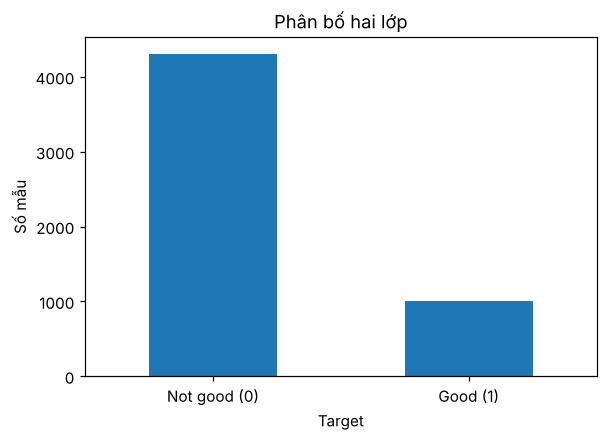

In [ ]:
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100
class_distribution = pd.DataFrame({
    "Số mẫu": class_count,
    "Tỷ lệ (%)": class_percent.round(2)
})
class_distribution.index = ["Not good (0)", "Good (1)"]
display(class_distribution)

plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("Phân bố hai lớp")
plt.xlabel("Target")
plt.ylabel("Số mẫu")
plt.xticks(ticks=[0, 1], labels=["Not good (0)", "Good (1)"], rotation=0)
plt.show()

**Nhận xét:** `Good` là **minority class** (~19%), `Not good` là majority class (~81%). Mô hình luôn đoán `Not good` đã đạt Accuracy ~81% mà không phát hiện được rượu tốt nào → cần xem Recall, F1, PR-AUC.

### 4.3. Kiểm tra thang đo của các feature

In [ ]:
feature_scale = pd.DataFrame({
    "mean": df.drop(columns="target").mean(),
    "std": df.drop(columns="target").std(),
    "min": df.drop(columns="target").min(),
    "max": df.drop(columns="target").max()
}).sort_values("std", ascending=False)
display(feature_scale.round(4))

                          mean      std     min      max
total sulfur dioxide  114.1090  56.7742  6.0000  440.000
free sulfur dioxide    30.0367  17.8050  1.0000  289.000
residual sugar          5.0485   4.5002  0.6000   65.800
fixed acidity           7.2152   1.3197  3.8000   15.900
alcohol                10.5492   1.1859  8.0000   14.900
type_white              0.7445   0.4362  0.0000    1.000
volatile acidity        0.3441   0.1682  0.0800    1.580
pH                      3.2247   0.1604  2.7200    4.010
sulphates               0.5334   0.1497  0.2200    2.000
citric acid             0.3185   0.1472  0.0000    1.660
chlorides               0.0567   0.0369  0.0090    0.611
density                 0.9945   0.0030  0.9871    1.039


Các feature có thang đo rất khác nhau (ví dụ `total sulfur dioxide` có std ~ 57, trong khi `chlorides` chỉ ~ 0.04 và `density` ~ 0.003) → cần `StandardScaler`, nhất là với Logistic Regression có regularization, KNN, SVM và SMOTE (dựa trên khoảng cách).

### 4.4. Tương quan của feature với nhãn

                      Tương quan với target
density                             -0.2950
chlorides                           -0.1610
volatile acidity                    -0.1444
residual sugar                      -0.0849
total sulfur dioxide                -0.0673
fixed acidity                       -0.0498
free sulfur dioxide                  0.0113
sulphates                            0.0368
pH                                   0.0483
citric acid                          0.0607
type_white                           0.0811
alcohol                              0.4177


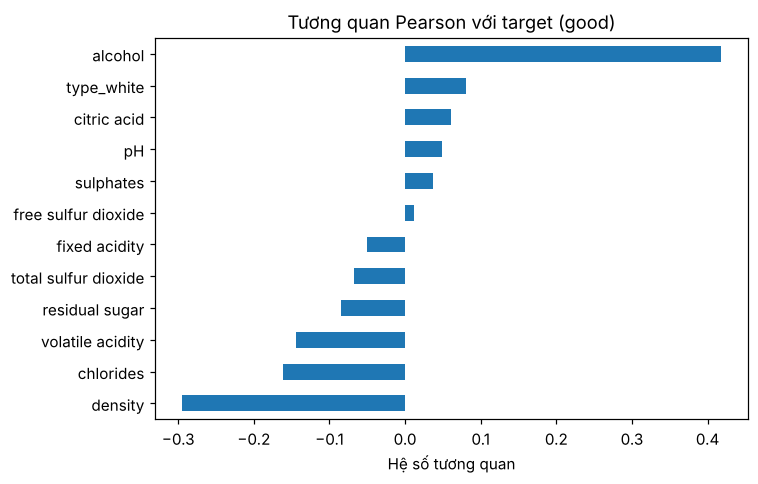

In [ ]:
corr = df.corr()["target"].drop("target").sort_values()
display(corr.round(4).to_frame("Tương quan với target"))

plt.figure(figsize=(7, 4.5))
corr.plot(kind="barh")
plt.title("Tương quan Pearson với target (good)")
plt.xlabel("Hệ số tương quan")
plt.tight_layout()
plt.show()

`alcohol` tương quan dương mạnh nhất với chất lượng cao (+0.42); `density` (−0.30), `chlorides` (−0.16) và `volatile acidity` (−0.14) tương quan âm. Các tương quan đều ở mức yếu đến trung bình, nên bài toán không dễ và Recall của lớp Good sẽ bị giới hạn.

## Phần 5. Train/Test split với `stratify=y`

In [ ]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
ratio = pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
    "Train (số mẫu)": y_train.value_counts().sort_index(),
    "Test (số mẫu)": y_test.value_counts().sort_index(),
})
ratio.index = ["Not good (0)", "Good (1)"]
display(ratio)

X_train: (4256, 12)  X_test: (1064, 12)
              Train (%)  Test (%)  Train (số mẫu)  Test (số mẫu)
Not good (0)      81.04     81.02            3449            862
Good (1)          18.96     18.98             807            202


Tập test được giữ nguyên, **không dùng để chọn mô hình**; mọi so sánh thực hiện bằng Cross Validation trên tập train.

## Phần 6. Metric, Stratified K-Fold và baseline

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_summary(estimator, X_data, y_data):
    s = cross_validate(estimator, X_data, y_data, cv=skf, scoring=scoring)
    row = {}
    for m in metric_cols:
        row[m + "_mean"] = s["test_" + m].mean()
        row[m + "_std"] = s["test_" + m].std()
    return row

def mean_table(results):
    return pd.DataFrame(results).T[[m + "_mean" for m in metric_cols]].rename(
        columns=lambda c: c.replace("_mean", ""))

def std_table(results):
    return pd.DataFrame(results).T[[m + "_std" for m in metric_cols]].rename(
        columns=lambda c: c.replace("_std", ""))

### 6.1. Baseline chỉ đoán lớp đa số (Dummy)

In [ ]:
dummy_res = cv_summary(
    SamplingPipeline(DummyClassifier(strategy="most_frequent"), None, scale=False),
    X_train, y_train)
display(pd.Series({m: dummy_res[m + "_mean"] for m in metric_cols}, name="Dummy").round(4))

accuracy     0.8104
precision    0.0000
recall       0.0000
f1           0.0000
roc_auc      0.5000
pr_auc       0.1896


Dummy có Accuracy ~81% nhưng Recall = 0, F1 = 0, ROC-AUC = 0.5: Accuracy cao **không có nghĩa** mô hình tốt.

### 6.2. Tác dụng của StandardScaler (Logistic Regression)

In [ ]:
lr = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
scale_compare = {
    "LogReg - Raw": cv_summary(SamplingPipeline(lr, None, scale=False), X_train, y_train),
    "LogReg - StandardScaler": cv_summary(SamplingPipeline(lr, None, scale=True), X_train, y_train),
}
display(mean_table(scale_compare).round(4))
print("\nStd giữa các fold:")
display(std_table(scale_compare).round(4))

                         accuracy  precision  recall      f1  roc_auc  pr_auc
LogReg - Raw               0.8242     0.5748  0.2949  0.3885   0.8254  0.5098
LogReg - StandardScaler    0.8278     0.5909  0.3086  0.4044   0.8315  0.5261

Std giữa các fold:
                         accuracy  precision  recall      f1  roc_auc  pr_auc
LogReg - Raw               0.0049     0.0340  0.0198  0.0109   0.0120  0.0238
LogReg - StandardScaler    0.0065     0.0426  0.0191  0.0167   0.0131  0.0215


## Phần 7. Xử lý Class Imbalance
### 7.1. Số mẫu train trước/sau khi lấy mẫu
Chỉ minh họa số lượng; huấn luyện chính thức dùng `SamplingPipeline` để lấy mẫu *bên trong* từng fold.

In [ ]:
scaler_demo = StandardScaler().fit(X_train)
X_train_scaled_demo = scaler_demo.transform(X_train)
rows = {"Gốc": y_train.value_counts().sort_index().tolist()}
for name, smp in [("Random Over-Sampling", RandomOverSampler()),
                  ("Random Under-Sampling", RandomUnderSampler()),
                  ("SMOTE", SMOTE())]:
    _, y_new = smp.fit_resample(X_train_scaled_demo, y_train.values)
    rows[name] = pd.Series(y_new).value_counts().sort_index().tolist()
display(pd.DataFrame(rows, index=["Not good (0)", "Good (1)"]).T)

                       Not good (0)  Good (1)
Gốc                            3449       807
Random Over-Sampling           3449      3449
Random Under-Sampling           807       807
SMOTE                          3449      3449


### 7.2. So sánh các phương án bằng Stratified 5-Fold CV (Logistic Regression)

In [ ]:
samplers = {
    "LogReg (không sampling)": None,
    "LogReg + Over-Sampling": RandomOverSampler(),
    "LogReg + Under-Sampling": RandomUnderSampler(),
    "LogReg + SMOTE": SMOTE(),
}
sampling_res = {name: cv_summary(SamplingPipeline(lr, smp, scale=True), X_train, y_train)
                for name, smp in samplers.items()}

sampling_mean = mean_table(sampling_res)
display(sampling_mean.sort_values("f1", ascending=False).round(4))
print("\nStd giữa các fold:")
display(std_table(sampling_res).round(4))

                         accuracy  precision  recall      f1  roc_auc  pr_auc
LogReg + Under-Sampling    0.7397     0.4044  0.7881  0.5344   0.8286  0.5180
LogReg + Over-Sampling     0.7399     0.4044  0.7806  0.5324   0.8303  0.5226
LogReg + SMOTE             0.7408     0.4047  0.7744  0.5313   0.8299  0.5223
LogReg (không sampling)    0.8278     0.5909  0.3086  0.4044   0.8315  0.5261

Std giữa các fold:
                         accuracy  precision  recall      f1  roc_auc  pr_auc
LogReg (không sampling)    0.0065     0.0426  0.0191  0.0167   0.0131  0.0215
LogReg + Over-Sampling     0.0152     0.0182  0.0353  0.0196   0.0129  0.0222
LogReg + Under-Sampling    0.0121     0.0154  0.0331  0.0195   0.0123  0.0215
LogReg + SMOTE             0.0136     0.0158  0.0341  0.0170   0.0133  0.0234


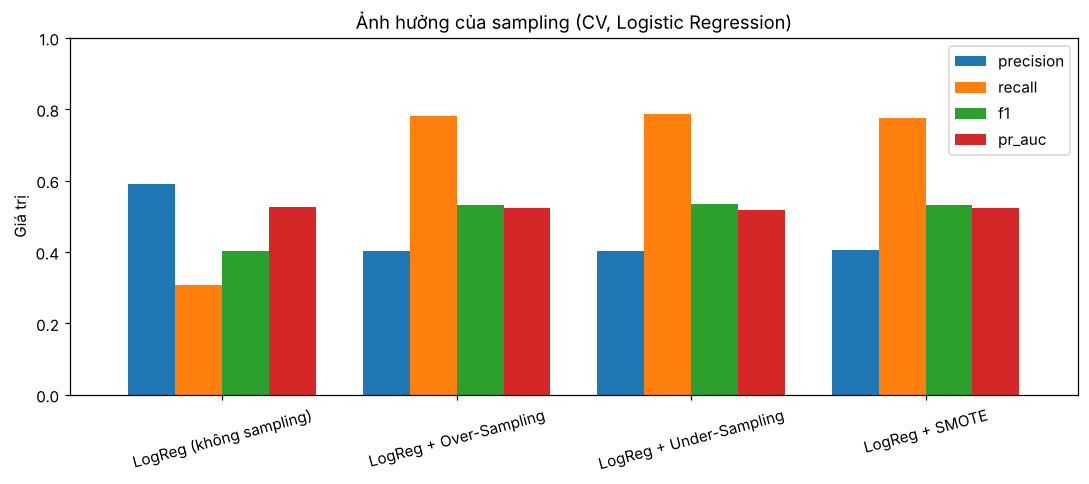

In [ ]:
ax = sampling_mean[["precision", "recall", "f1", "pr_auc"]].plot(
    kind="bar", figsize=(10, 4.5), width=0.8)
ax.set_title("Ảnh hưởng của sampling (CV, Logistic Regression)")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
best_sampling = sampling_mean["f1"].idxmax()
print("Phương án sampling có F1 (CV) cao nhất:", best_sampling)

Phương án sampling có F1 (CV) cao nhất: LogReg + Under-Sampling


## Phần 8. So sánh các classifier
Giữ nguyên quy trình `StandardScaler → Sampling → Classifier`, thay classifier. Với mỗi classifier ta so sánh **không sampling** và **Over-Sampling** (kỹ thuật đơn giản, thường dùng làm mặc định).

In [ ]:
models = {
    "LogReg": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}
model_res = {}
for name, mdl in models.items():
    model_res[name + " | không sampling"] = cv_summary(
        SamplingPipeline(mdl, None, scale=True), X_train, y_train)
    model_res[name + " | Over-Sampling"] = cv_summary(
        SamplingPipeline(mdl, RandomOverSampler(), scale=True), X_train, y_train)

model_mean = mean_table(model_res)
display(model_mean.sort_values("f1", ascending=False).round(4))

                                accuracy  precision  recall      f1  roc_auc  pr_auc
SVM (RBF) | Over-Sampling         0.7491     0.4158  0.7943  0.5457   0.8418  0.5370
LogReg | Over-Sampling            0.7399     0.4044  0.7806  0.5324   0.8303  0.5226
Random Forest | Over-Sampling     0.8372     0.5870  0.4845  0.5303   0.8471  0.5668
Decision Tree | Over-Sampling     0.7173     0.3757  0.7348  0.4966   0.7460  0.3843
KNN | Over-Sampling               0.7164     0.3709  0.7101  0.4870   0.7720  0.3972
KNN | không sampling              0.8243     0.5496  0.4225  0.4771   0.7849  0.4467
Random Forest | không sampling    0.8409     0.6520  0.3494  0.4541   0.8445  0.5736
Decision Tree | không sampling    0.8069     0.4881  0.3495  0.4051   0.7346  0.3911
LogReg | không sampling           0.8278     0.5909  0.3086  0.4044   0.8315  0.5261
SVM (RBF) | không sampling        0.8374     0.6711  0.2875  0.4006   0.8035  0.5453


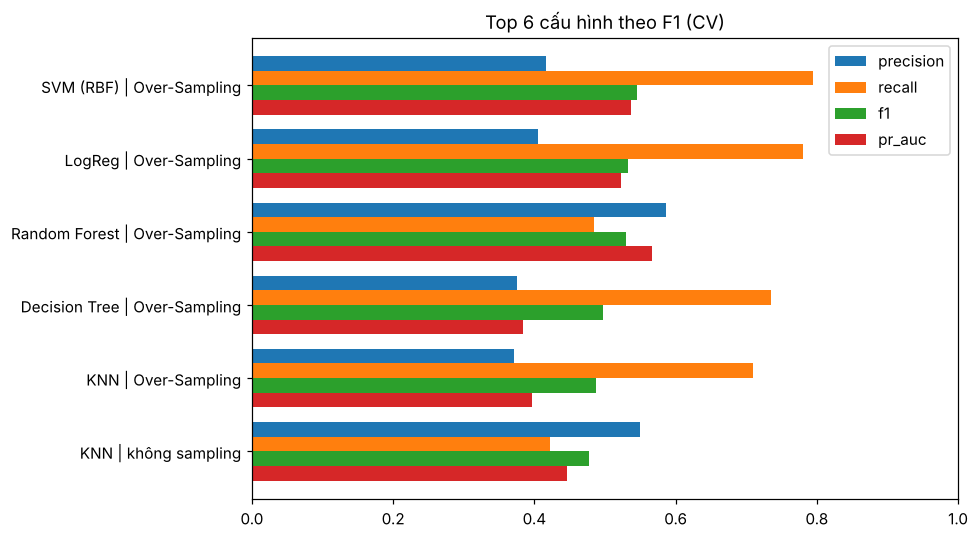

In [ ]:
top = model_mean.sort_values("f1", ascending=False).head(6)
ax = top[["precision", "recall", "f1", "pr_auc"]].plot(
    kind="barh", figsize=(9, 5), width=0.8)
ax.invert_yaxis()
ax.set_title("Top 6 cấu hình theo F1 (CV)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## Phần 9. Chọn cấu hình tốt nhất và đánh giá trên tập test
Chọn theo **F1 trung bình trong CV** (cân bằng Precision và Recall cho minority class). Sau đó fit lại trên toàn bộ train và đánh giá **một lần** trên test.

In [ ]:
best_name = model_mean["f1"].idxmax()
best_model_name, best_samp_name = [s.strip() for s in best_name.split("|")]
best_sampler = RandomOverSampler() if best_samp_name == "Over-Sampling" else None
print("Cấu hình được chọn:", best_name)

final_model = SamplingPipeline(models[best_model_name], best_sampler, scale=True)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_score = final_model.decision_function(X_test)

test_res = pd.Series({
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_score),
    "pr_auc": average_precision_score(y_test, y_score),
}, name=best_name)
display(test_res.round(4).to_frame())

Cấu hình được chọn: SVM (RBF) | Over-Sampling
           SVM (RBF) | Over-Sampling
accuracy                      0.7406
precision                     0.4089
recall                        0.8218
f1                            0.5461
roc_auc                       0.8526
pr_auc                        0.5001


### 9.1. Confusion Matrix

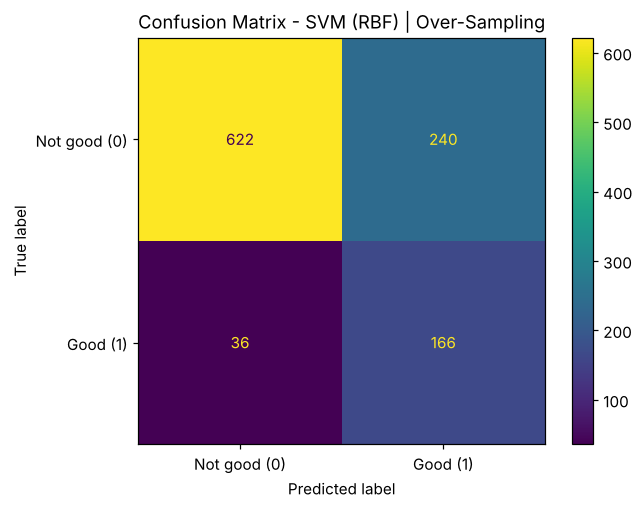

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not good (0)", "Good (1)"])
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

### 9.2. Classification Report

In [ ]:
print(classification_report(
    y_test, y_pred, target_names=["Not good (0)", "Good (1)"],
    digits=4, zero_division=0))

              precision    recall  f1-score   support

Not good (0)     0.9453    0.7216    0.8184       862
    Good (1)     0.4089    0.8218    0.5461       202

    accuracy                         0.7406      1064
   macro avg     0.6771    0.7717    0.6822      1064
weighted avg     0.8434    0.7406    0.7667      1064



### 9.3. Precision-Recall Curve

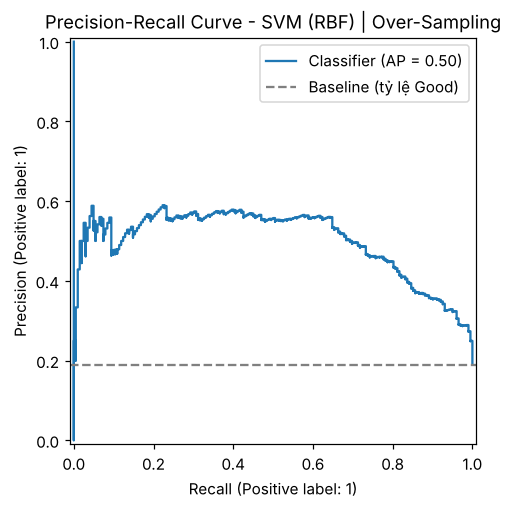

In [ ]:
PrecisionRecallDisplay.from_predictions(y_test, y_score)
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Baseline (tỷ lệ Good)")
plt.legend()
plt.title(f"Precision-Recall Curve - {best_name}")
plt.show()

## Phần 10. Nhận xét

### Nhận xét kết quả

**1. Dữ liệu và imbalance.** Sau khi loại 1177 dòng trùng còn 5320 mẫu; lớp Good (quality ≥ 7) chiếm 18.96% (1009 mẫu), lớp Not good chiếm 81.04%. Mô hình Dummy luôn đoán Not good đạt Accuracy 0.8104 nhưng Recall = 0, F1 = 0, ROC-AUC = 0.5.

**2. StandardScaler.** Logistic Regression khi chuẩn hóa tốt hơn không chuẩn hóa ở mọi metric: F1 0.404 so với 0.389, Recall 0.309 so với 0.295, PR-AUC 0.526 so với 0.510. Mức cải thiện nhỏ vì chỉ có vài feature có thang đo lệch hẳn (total sulfur dioxide, free sulfur dioxide, residual sugar), nhưng việc chuẩn hóa vẫn bắt buộc với KNN, SVM và SMOTE.

**3. Sampling (Logistic Regression, CV).** Không sampling: Accuracy 0.828, Recall chỉ 0.309, F1 0.404. Cả ba kỹ thuật đều đưa Recall lên khoảng 0.77–0.79 và F1 lên khoảng 0.53, đổi lại Precision giảm từ 0.591 xuống 0.404 và Accuracy giảm từ 0.828 xuống 0.740. PR-AUC và ROC-AUC gần như không đổi (PR-AUC 0.518–0.526), nghĩa là sampling không làm mô hình phân biệt tốt hơn mà chỉ dịch ngưỡng quyết định về phía lớp Good. Ba kỹ thuật cho kết quả gần như bằng nhau (F1 0.531–0.534, chênh lệch nhỏ hơn std ~0.02) nên không thể kết luận kỹ thuật nào hơn; Over-Sampling được chọn vì đơn giản và không bỏ dữ liệu như Under-Sampling.

**4. So sánh classifier.** Theo F1 (CV), SVM-RBF + Over-Sampling đứng đầu (F1 0.546, Recall 0.794, Precision 0.416), sau đó là Logistic Regression + Over-Sampling (0.532) và Random Forest + Over-Sampling (0.530). Chênh lệch giữa ba cấu hình đầu nhỏ hơn std của F1 (~0.02) nên về thống kê chúng gần tương đương. Random Forest có PR-AUC cao nhất (0.567–0.574) và Precision cao hơn: nếu ưu tiên Precision hoặc khả năng xếp hạng thì RF là lựa chọn tốt. Decision Tree và KNN kém hơn rõ (PR-AUC 0.38–0.45).

**5. Kết quả cuối trên test.** SVM-RBF + Over-Sampling: Accuracy 0.7406, Precision (Good) 0.4089, Recall (Good) 0.8218, F1 0.5461, ROC-AUC 0.8526, PR-AUC 0.5001. Mô hình phát hiện 82% rượu chất lượng cao nhưng khoảng 59% dự đoán Good là báo nhầm. Kết quả test nhất quán với CV (F1 0.546 so với 0.546), cho thấy không có dấu hiệu overfitting hay leakage.

**6. Hạn chế.** Mức tương quan giữa các feature và nhãn chỉ yếu đến trung bình (alcohol +0.42), nên Precision của lớp Good khó vượt 0.5–0.6 mà không hy sinh Recall. Không dùng tuning hyperparameter; việc tinh chỉnh (ví dụ `C`, `gamma` của SVM, hoặc chọn ngưỡng quyết định) có thể cải thiện thêm.

**Kết luận:** với dữ liệu wine quality mất cân bằng, Accuracy (0.74–0.84) không phản ánh khả năng phát hiện rượu tốt; cần dựa vào Recall, F1, PR-AUC. Cấu hình chọn theo F1 CV là SVM-RBF + Over-Sampling, đạt Recall 0.82 và F1 0.55 trên test.